In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [58]:
df = pd.read_csv("Apartments Prices Dataset(Target column price).csv")
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [59]:
df.shape

(5578, 11)

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   price           5572 non-null   str  
 1   area_sqm        5545 non-null   str  
 2   rooms           5550 non-null   str  
 3   bathrooms       5480 non-null   str  
 4   floor_level     5578 non-null   str  
 5   year_built      5578 non-null   int64
 6   seller_type     5387 non-null   str  
 7   view            5556 non-null   str  
 8   price_per_sqm   5534 non-null   str  
 9   payment_method  5566 non-null   str  
 10  finishing_type  5578 non-null   str  
dtypes: int64(1), str(10)
memory usage: 479.5 KB


In [61]:
df.isnull().sum().sort_values(ascending=False)

seller_type       191
bathrooms          98
price_per_sqm      44
area_sqm           33
rooms              28
view               22
payment_method     12
price               6
floor_level         0
year_built          0
finishing_type      0
dtype: int64

In [62]:
df = df.dropna(subset=['price'])

In [63]:
df.drop('price_per_sqm', axis=1, inplace=True)

In [64]:
numerical_cols = [
    'area_sqm', 'rooms', 'bathrooms',
    'floor_level', 'year_built'
]

categorical_cols = [
    'seller_type', 'view',
    'payment_method', 'finishing_type'
]

In [65]:
print(df[numerical_cols].dtypes)

area_sqm         str
rooms            str
bathrooms        str
floor_level      str
year_built     int64
dtype: object


In [66]:
print(df['floor_level'].unique())

<StringArray>
[     '3',      '6',      '4',     '13',      '9',      '2', 'Ground',
      '7',      '1',     '12',     '10',      '8',      '5',     '22',
     '64',     '11',     '18',     '16',     '15',     '17',     '14',
     '32']
Length: 22, dtype: str


In [67]:
df['floor_level'] = df['floor_level'].replace('Ground', '0')

df['floor_level'] = pd.to_numeric(
    df['floor_level'],
    errors='coerce'
)

In [68]:
for col in ['area_sqm', 'rooms', 'bathrooms']:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace(',', '', regex=False)
        .str.extract(r'(\d+\.?\d*)')[0],
        errors='coerce'
    )

In [69]:
print(df[numerical_cols].dtypes)

area_sqm       float64
rooms          float64
bathrooms      float64
floor_level      int64
year_built       int64
dtype: object


In [70]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [71]:
print(df.isnull().sum())

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
payment_method    0
finishing_type    0
dtype: int64


In [72]:
df['price'] = pd.to_numeric(
    df['price'].astype(str)
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

In [73]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

categorical_cols = [
    'seller_type',
    'view',
    'payment_method',
    'finishing_type'
]

numerical_cols = [
    'area_sqm',
    'rooms',
    'bathrooms',
    'floor_level',
    'year_built'
]

X = df.drop('price', axis=1)
y = df['price']

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

encoded_cols = encoder.fit_transform(X[categorical_cols])

encoded_df = pd.DataFrame(
    encoded_cols,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X.index
)

X = X.drop(categorical_cols, axis=1)
X = pd.concat([X, encoded_df], axis=1)

In [75]:
X = df.drop('price', axis=1)
y = df['price']

In [76]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

encoded_cols = encoder.fit_transform(X[categorical_cols])

encoded_df = pd.DataFrame(
    encoded_cols,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X.index
)

In [77]:
X = X.drop(categorical_cols, axis=1)

X = pd.concat([X, encoded_df], axis=1)

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [79]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [80]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

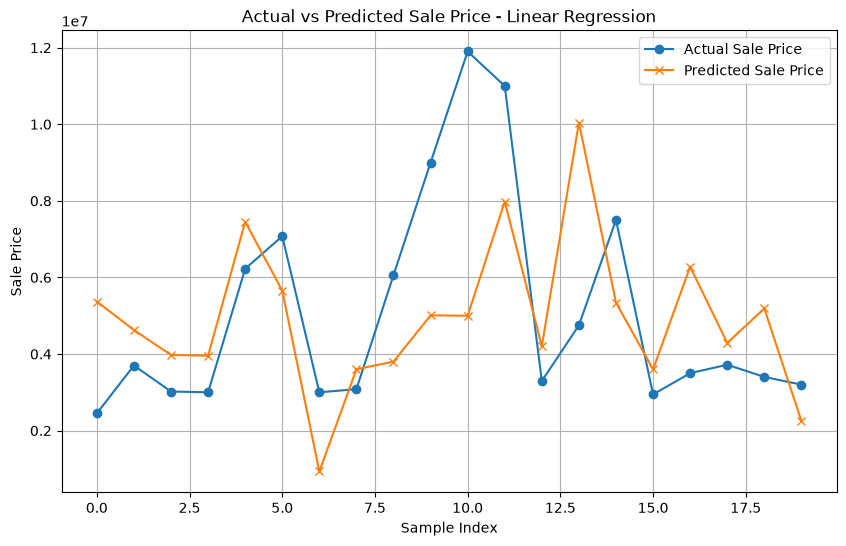

  7%|▋         | 1/15 [00:00<00:01,  8.32it/s]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.124792e+16, tolerance: 8.142e+12
  model = cd_fast.enet_coordinate_descent(


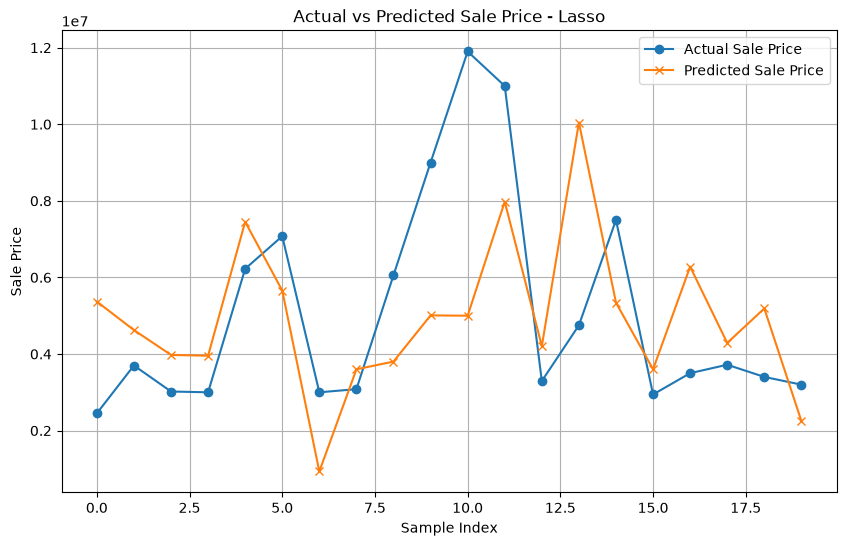

 13%|█▎        | 2/15 [00:00<00:02,  5.98it/s]

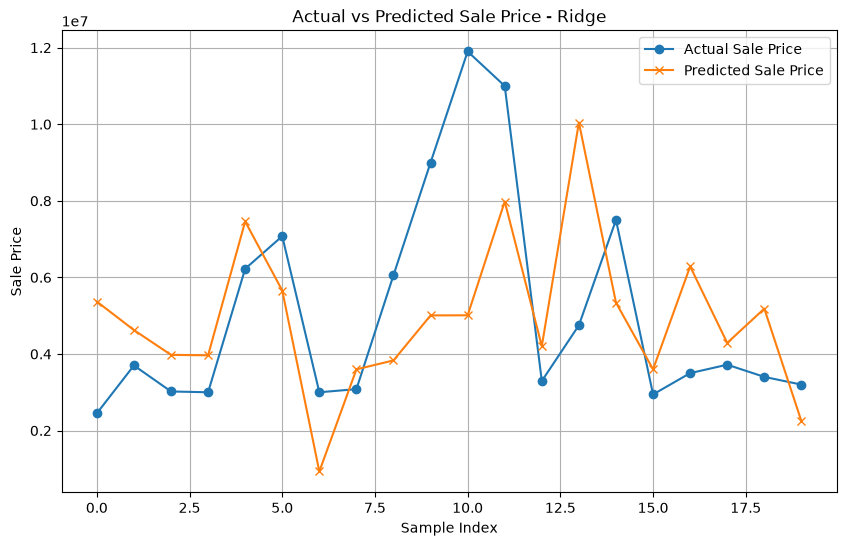

 20%|██        | 3/15 [00:00<00:01,  6.85it/s]

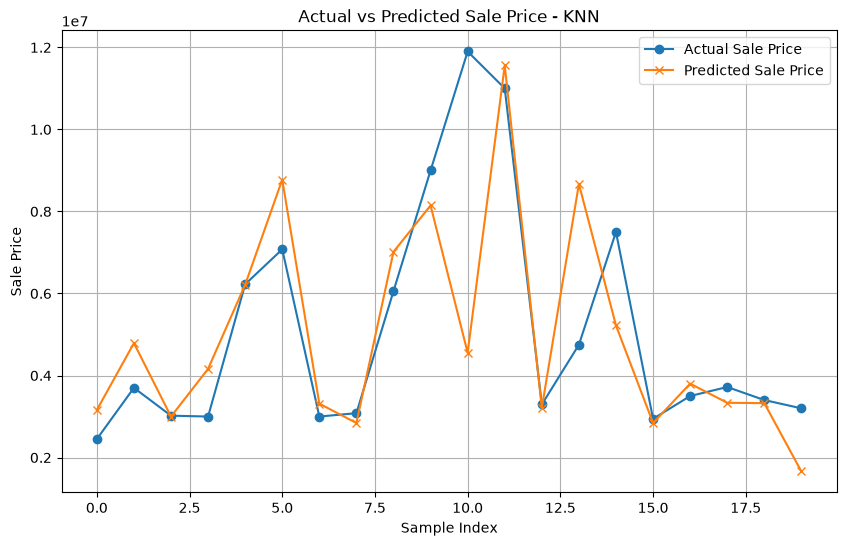

 27%|██▋       | 4/15 [00:00<00:02,  5.37it/s]

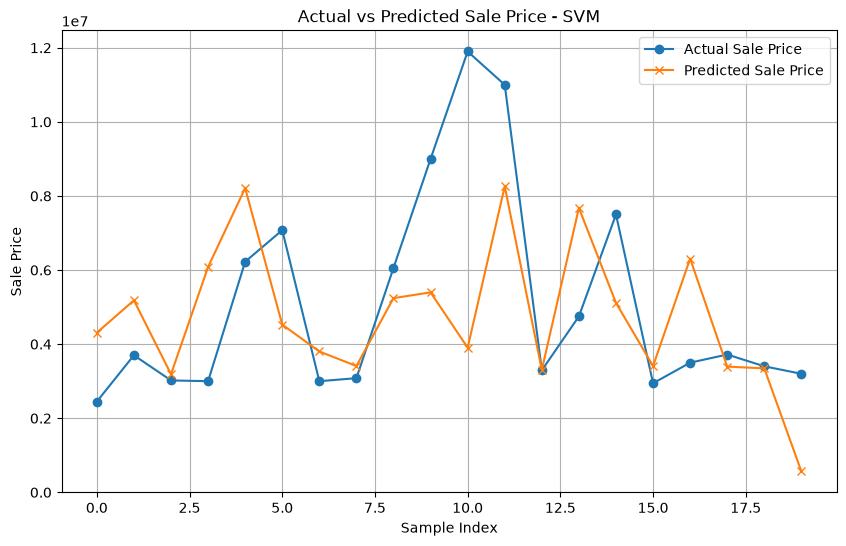

 33%|███▎      | 5/15 [00:01<00:04,  2.18it/s]

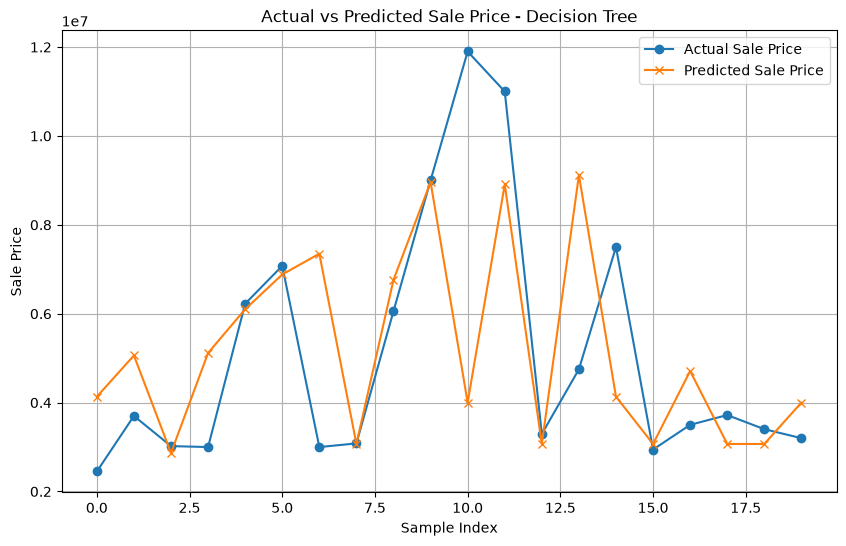

 40%|████      | 6/15 [00:01<00:03,  2.64it/s]

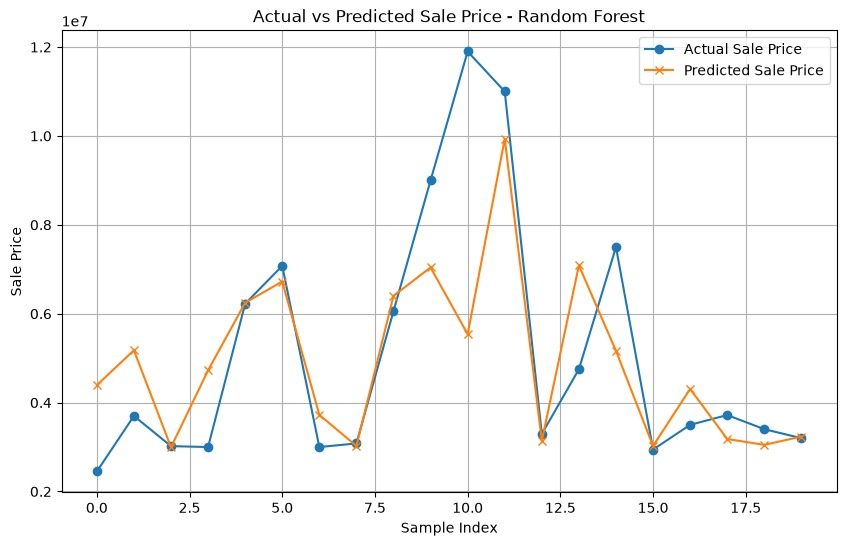

 47%|████▋     | 7/15 [00:02<00:03,  2.35it/s]

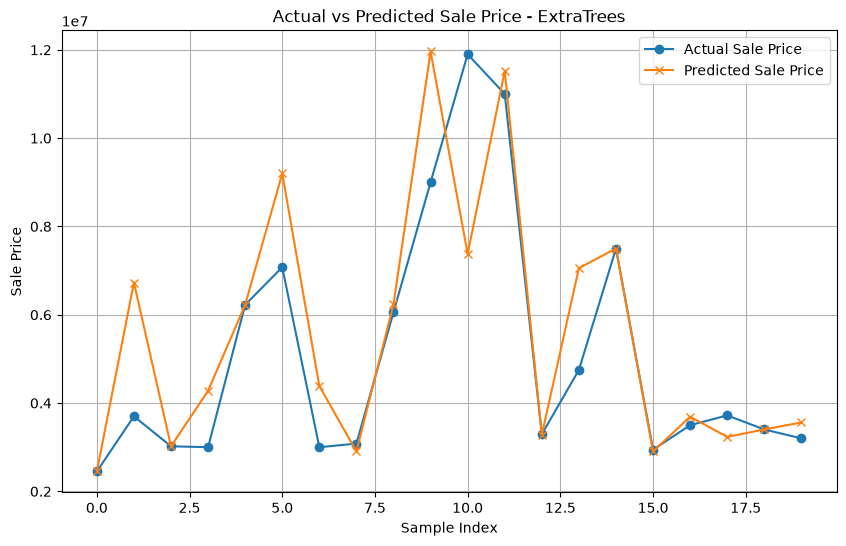

 53%|█████▎    | 8/15 [00:03<00:05,  1.32it/s]

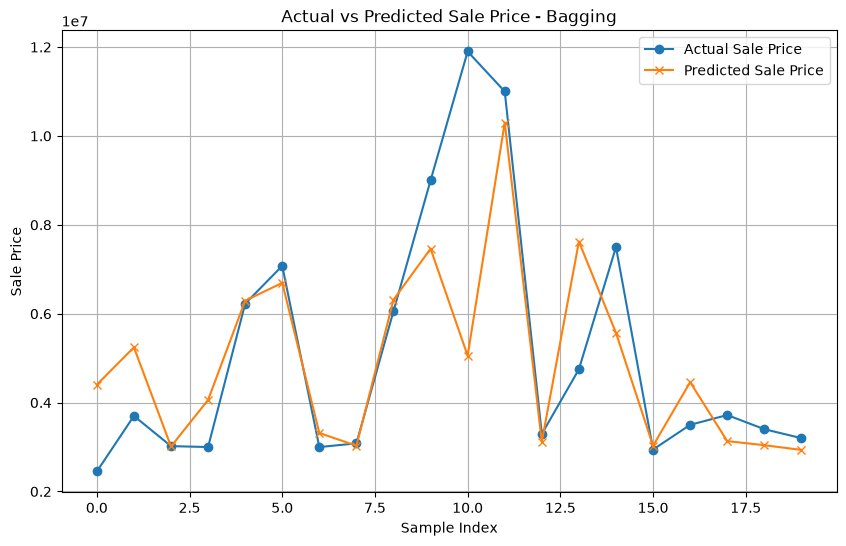

 60%|██████    | 9/15 [00:04<00:04,  1.39it/s]

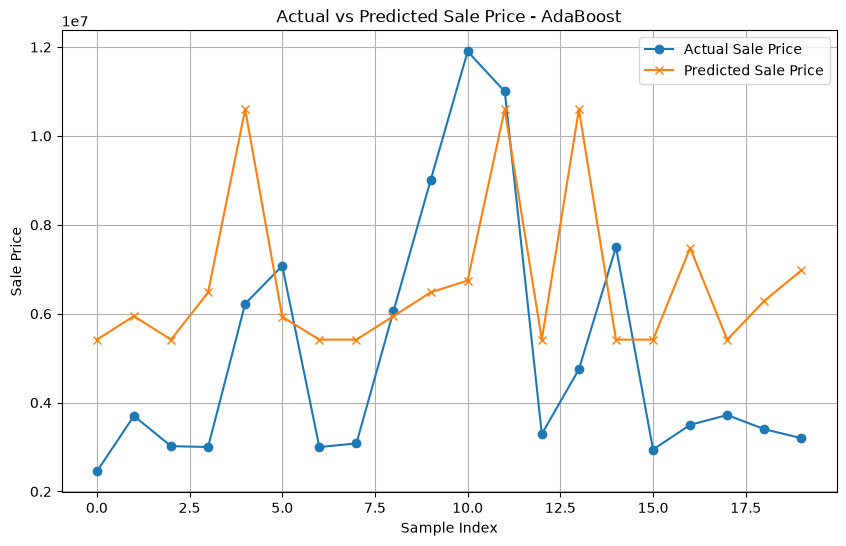

 67%|██████▋   | 10/15 [00:04<00:02,  1.73it/s]

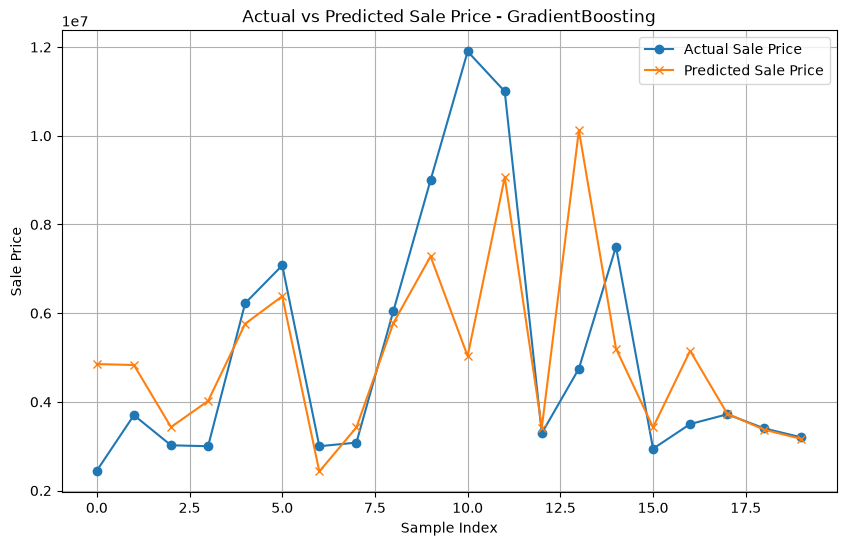

 73%|███████▎  | 11/15 [00:05<00:02,  1.83it/s]

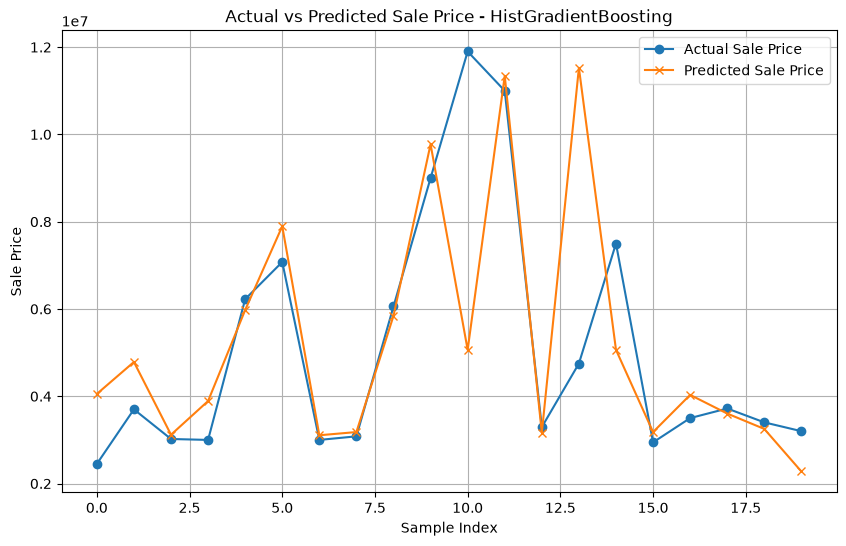

 80%|████████  | 12/15 [00:05<00:01,  1.89it/s]

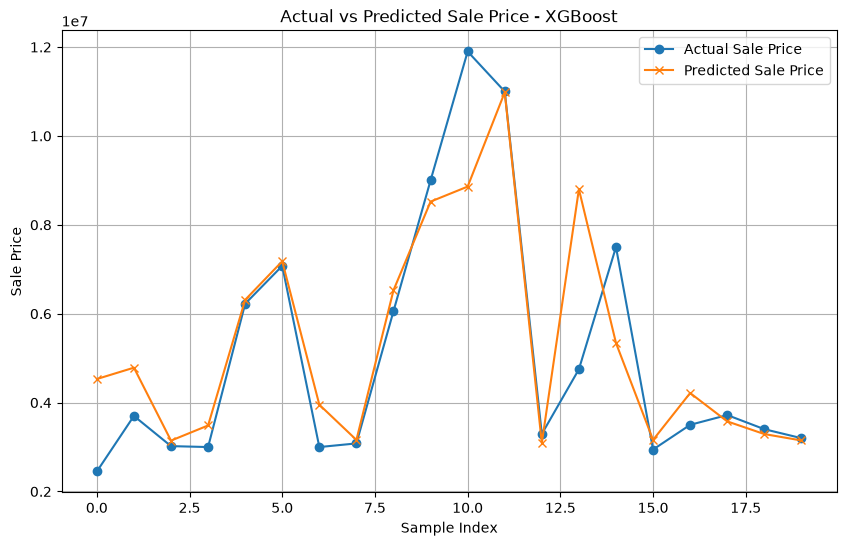

 87%|████████▋ | 13/15 [00:05<00:00,  2.19it/s]

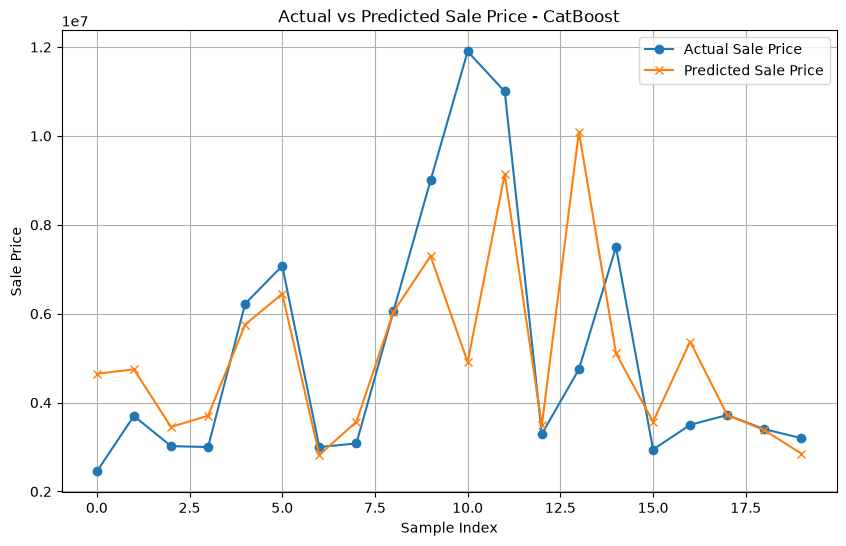

 93%|█████████▎| 14/15 [00:06<00:00,  2.34it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000245 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 332
[LightGBM] [Info] Number of data points in the train set: 4457, number of used features: 27
[LightGBM] [Info] Start training from score 5973989.038815


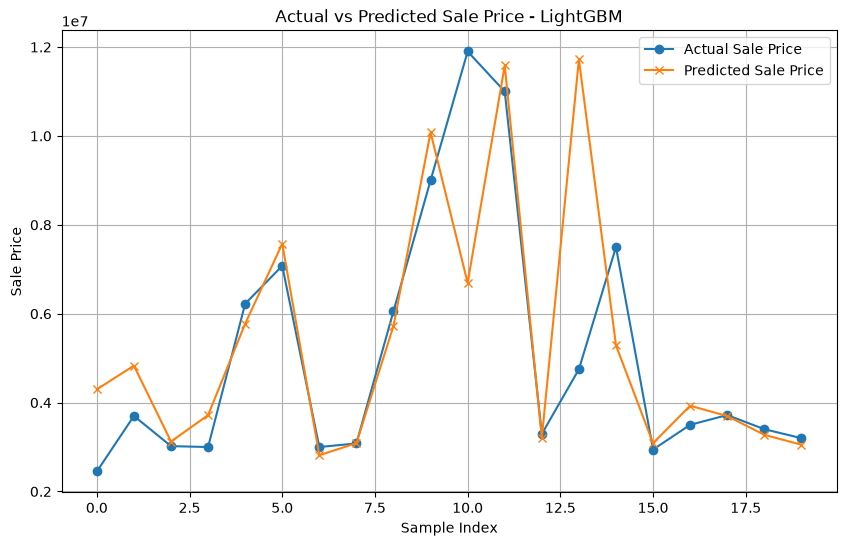

100%|██████████| 15/15 [00:06<00:00,  2.27it/s]


In [81]:
errors = {}

for model_name, model in tqdm(models.items()):

    # Training
    model.fit(X_train, y_train)

    # Train Metrics
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(
        model, X_train, y_train
    )

    # Test Metrics
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(
        model, X_test, y_test
    )

    # Save Results
    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Actual vs Predicted (First 20 Samples)
    y_test_plot = y_test.iloc[:20].values
    y_pred_plot = model.predict(X_test.iloc[:20])

    plt.figure(figsize=(10, 6))

    plt.plot(range(len(y_test_plot)), y_test_plot,
             label='Actual Sale Price', marker='o')

    plt.plot(range(len(y_test_plot)), y_pred_plot,
             label='Predicted Sale Price', marker='x')

    plt.xlabel('Sample Index')
    plt.ylabel('Sale Price')
    plt.title('Actual vs Predicted Sale Price - ' + model_name)

    plt.legend()
    plt.grid()
    plt.show()

In [83]:
results_df = pd.DataFrame(errors).T
display(results_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,2.080744e+06,2.386729e+06,1.186796e+13,2.327920e+13,3.444991e+06,4.824852e+06,0.350311,0.208501
Lasso,2.080742e+06,2.385850e+06,1.186796e+13,2.327600e+13,3.444991e+06,4.824521e+06,0.350311,0.208610
Ridge,2.080664e+06,2.386060e+06,1.186897e+13,2.327601e+13,3.445138e+06,4.824522e+06,0.350256,0.208609
KNN,1.340512e+06,1.911327e+06,7.440347e+12,2.001684e+13,2.727700e+06,4.474018e+06,0.592693,0.319422
SVM,2.292420e+06,2.552131e+06,1.508908e+13,2.639182e+13,3.884466e+06,5.137296e+06,0.173978,0.102671
Decision Tree,1.305739e+06,1.964260e+06,4.502123e+12,1.701780e+13,2.121821e+06,4.125264e+06,0.753540,0.421390
Random Forest,1.269697e+06,1.838788e+06,4.240354e+12,1.584315e+13,2.059212e+06,3.980345e+06,0.767870,0.461329
ExtraTrees,4.426480e+04,1.439330e+06,7.001379e+10,1.431183e+13,2.646012e+05,3.783098e+06,0.996167,0.513394
Bagging,1.270847e+06,1.816049e+06,4.085768e+12,1.522068e+13,2.021328e+06,3.901369e+06,0.776333,0.482493
AdaBoost,2.892506e+06,3.119499e+06,1.296026e+13,2.231073e+13,3.600036e+06,4.723423e+06,0.290516,0.241429


In [90]:
best_model_name = min(
    errors,
    key=lambda model: errors[model]['MAE Test']
)

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("MAE Test:", errors[best_model_name]['MAE Test'])

Best Model: ExtraTrees
MAE Test: 1439329.6384444372


In [91]:
import gradio as gr

In [92]:
def predict(area_sqm, rooms, bathrooms, floor_level,
            year_built, seller_type, view,
            payment_method, finishing_type):

    new_data = pd.DataFrame([{
        'area_sqm': area_sqm,
        'rooms': rooms,
        'bathrooms': bathrooms,
        'floor_level': floor_level,
        'year_built': year_built,
        'seller_type': seller_type,
        'view': view,
        'payment_method': payment_method,
        'finishing_type': finishing_type
    }])

    encoded_new = encoder.transform(new_data[categorical_cols])

    encoded_df = pd.DataFrame(
        encoded_new,
        columns=encoder.get_feature_names_out(categorical_cols)
    )

    X_new = pd.concat([
        new_data[numerical_cols].reset_index(drop=True),
        encoded_df
    ], axis=1)

    X_new = X_new.reindex(columns=X_train.columns, fill_value=0)

    prediction = best_model.predict(X_new)[0]

    return f"Predicted Apartment Price: {prediction:,.0f} EGP"

In [93]:
interface = gr.Interface(
    fn=predict,

    inputs=[
        gr.Number(label="Area (sqm)"),
        gr.Number(label="Rooms"),
        gr.Number(label="Bathrooms"),
        gr.Number(label="Floor Level"),
        gr.Number(label="Year Built"),

        gr.Dropdown(
            choices=df['seller_type'].dropna().unique().tolist(),
            label="Seller Type"
        ),

        gr.Dropdown(
            choices=df['view'].dropna().unique().tolist(),
            label="View"
        ),

        gr.Dropdown(
            choices=df['payment_method'].dropna().unique().tolist(),
            label="Payment Method"
        ),

        gr.Dropdown(
            choices=df['finishing_type'].dropna().unique().tolist(),
            label="Finishing Type"
        )
    ],

    outputs=gr.Textbox(label="Predicted Price"),

    title="Apartment Price Prediction",

    description="Enter apartment details to predict its price in EGP."
)

interface.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
